In [1]:
from mylib.statistic_test import *

code_id = "0880 - Path Integration"
loc = join(figpath, 'Dsp', code_id)
mkdir(loc)

dir_name0 = r'D:\Data\FinalResults\Dsp\Reforming Neural Trajectory Analysis'
pass

d:\Softwares\Anaconda2025\envs\maze\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


        D:\Data\FinalResults\Dsp\0880 - Path Integration is already existed!


# Identify PI-based map vis decoding

In [ ]:
import numpy as np
from mylib.decoder.NaiveBayesianDecoder import NaiveBayesDecoder
from mylib.decoder.NaiveBayesianDecoderHD import NaiveBayesDecoderHD
import time

D = GetDMatrices(1, 48)
    
def compute_posterior_expected_loss_allo(y_test_all, y_uniq, proba):
    
    pel_all = np.zeros(y_test_all.shape[0], np.float64)
    for i in range(y_test_all.shape[0]):
        pel_all[i] = np.nansum(D[y_test_all[i]-1, y_uniq-1] * proba[i, :])
    return pel_all

def compute_posterior_expected_loss_ego(y_test, y_uniq, proba):
    pel_ego = np.zeros(y_test.shape[0], np.float64)
    for i in range(y_test.shape[0]):
        pel_ego[i] = np.nansum(np.abs(y_test[i] -  y_uniq) * 2 * proba[i, :])
    return pel_ego

    
def decode_pi(trace: dict):
    print(f"{time.strftime('%Y-%m-%d %H:%M:%S')}")
    D = GetDMatrices(1, 48)
    # generate training set for R2, R3, R4
    idx = np.where(
        (trace['ms_time'] >= trace['node 0']['ms_time_behav'][0]-1) &
        (trace['ms_time'] <= trace['node 0']['ms_time_behav'][-1]+1) &
        (np.isnan(trace['spike_nodes_original']) == False)
    )[0]
    rawstd = np.std(trace['RawTraces'], axis=1, keepdims=True)
    raw_spikes = np.where(trace['RawTraces'] - rawstd*3 >= 0, 1, 0)
    X_train = raw_spikes[:, idx]
    y_train = trace['spike_nodes_original'][idx].astype(np.int64)
    
    gnb = NaiveBayesDecoder(maze_type=1, res=48)
    gnb.fit(X_train, y_train)
    
    y_test = []
    y_pred = []
    y_pred_ego = []
    r_test = []
    t_test = []
    for n, rt in zip(range(1,5), [1, 2, 3, 0]):
        print(f"Rt {rt}")
        idx = np.where(
            (trace['ms_time'] >= trace[f'node {n}']['ms_time_behav'][0]-1) &
            (trace['ms_time'] <= trace[f'node {n}']['ms_time_behav'][-1]+1) &
            (np.isnan(trace['spike_nodes_original']) == False)
        )[0]
        X_test_n = raw_spikes[:, idx]
        y_test_n = trace['spike_nodes_original'][idx].astype(np.int64)
        
        y_pred_n = gnb.predict(X_test_n, y_test_n)
        y_pred.append(y_pred_n)
        
        y_pred_ego_n = D[y_pred_n-1, 0]
        y_pred_ego.append(y_pred_ego_n)
        
        y_test.append(y_test_n)
        t_test.append(np.repeat("Data", y_test_n.shape[0]))
        r_test.append(np.repeat(n, y_test_n.shape[0]))
        
        
        # Shuffle test
        perm_idx = np.random.permutation(X_train.shape[0])
        y_pred_shuf = gnb.predict(X_test_n[perm_idx, :], y_test_n)
        y_pred.append(y_pred_shuf)
        y_pred_ego_shuf = D[y_pred_shuf-1, 0]
        y_pred_ego.append(y_pred_ego_shuf)
        y_test.append(y_test_n)
        t_test.append(np.repeat("Shuffle", y_test_n.shape[0]))
        r_test.append(np.repeat(n, y_test_n.shape[0]))


    # generate training set for R5, R6, R7
    idx = np.where(
        (trace['ms_time'] >= trace['node 5']['ms_time_behav'][0]-1) &
        (trace['ms_time'] <= trace['node 5']['ms_time_behav'][-1]+1) &
        (np.isnan(trace['spike_nodes_original']) == False)
    )[0]
    rawstd = np.std(trace['RawTraces'], axis=1, keepdims=True)
    raw_spikes = np.where(trace['RawTraces'] - rawstd*3 >= 0, 1, 0)
    X_train = raw_spikes[:, idx]
    y_train = trace['spike_nodes_original'][idx].astype(np.int64)
    
    gnb = NaiveBayesDecoder(maze_type=1, res=48)
    gnb.fit(X_train, y_train)
    
    for n, rt in zip(range(6,10), [4, 5, 6, 0]):
        print(f"Rt {rt}")
        idx = np.where(
            (trace['ms_time'] >= trace[f'node {n}']['ms_time_behav'][0]-1) &
            (trace['ms_time'] <= trace[f'node {n}']['ms_time_behav'][-1]+1) &
            (np.isnan(trace['spike_nodes_original']) == False)
        )[0]
        X_test_n = raw_spikes[:, idx]
        y_test_n = trace['spike_nodes_original'][idx].astype(np.int64)
        
        y_pred_n = gnb.predict(X_test_n, y_test_n)
        y_pred.append(y_pred_n)
        
        y_pred_ego_n = D[y_pred_n-1, 0]
        y_pred_ego.append(y_pred_ego_n)
        
        y_test.append(y_test_n)
        t_test.append(np.repeat("Data", y_test_n.shape[0]))
        r_test.append(np.repeat(n, y_test_n.shape[0]))
        
        
        # Shuffle test
        perm_idx = np.random.permutation(X_train.shape[0])
        y_pred_shuf = gnb.predict(X_test_n[perm_idx, :], y_test_n)
        y_pred.append(y_pred_shuf)
        y_pred_ego_shuf = D[y_pred_shuf-1, 0]
        y_pred_ego.append(y_pred_ego_shuf)
        y_test.append(y_test_n)
        t_test.append(np.repeat("Shuffle", y_test_n.shape[0]))
        r_test.append(np.repeat(n, y_test_n.shape[0]))
    
    print(f"{time.strftime('%Y-%m-%d %H:%M:%S')}     Done.\n\n\n")
        
    return (
        np.concatenate(y_test).astype(np.int64), 
        np.concatenate(y_pred).astype(np.int64), 
        np.concatenate(y_pred_ego).astype(np.float64), 
        np.concatenate(t_test), 
        np.concatenate(r_test).astype(np.int64)

    )


def get_lap_info(trace):
    lap_info = []
    beg, end = LapSplit(trace, trace['paradigm'])
    beg_time, end_time = trace['lap beg time'], trace['lap end time']

    ms_time = []
    for n, rt in zip(range(1,5), [1, 2, 3, 0]):
        idx = np.where(
            (trace['ms_time'] >= trace[f'node {n}']['ms_time_behav'][0]-1) &
            (trace['ms_time'] <= trace[f'node {n}']['ms_time_behav'][-1]+1) &
            (np.isnan(trace['spike_nodes_original']) == False)
        )[0]
        ms_time.append(trace['ms_time'][idx])
        ms_time.append(trace['ms_time'][idx])

    for n, rt in zip(range(6, 10), [4, 5, 6, 0]):
        idx = np.where(
            (trace['ms_time'] >= trace[f'node {n}']['ms_time_behav'][0]-1) &
            (trace['ms_time'] <= trace[f'node {n}']['ms_time_behav'][-1]+1) &
            (np.isnan(trace['spike_nodes_original']) == False)
        )[0]
        ms_time.append(trace['ms_time'][idx])
        ms_time.append(trace['ms_time'][idx])
    
    ms_time = np.concatenate(ms_time).astype(np.int64)
    lap_info = np.zeros_like(ms_time)-1
    for i in range(beg_time.shape[0]):
        idx = np.where((ms_time >= beg_time[i]-1) & (ms_time <= end_time[i]+1))[0]
        lap_info[idx] = i

    return lap_info, ms_time.astype(np.float64)/1000



# Save Decoder
save_dir = join(loc, "Decoded Results")
os.makedirs(save_dir, exist_ok=True)

if exists(join(figdata, f" {code_id}.pkl"))  == False:
    DecodePI = {
        "MiceID": [],
        "Session": [],
        "Allo Loss": [],
        "Ego Loss": [],
        "Distance": [],
        "Lap": [],
        "Route": [],
        "Type": [],
        "Time": []
    }
    D = GetDMatrices(1, 48)
    node_to_rt = {
        0: 0,
        1: 1,
        2: 2,
        3: 3,
        4: 0,
        5: 0,
        6: 4,
        7: 5,
        8: 6,
        9: 0
    }
    for mouse in [10212, 10224, 10227, 10232, 10275, 10276]:
        file_idx = np.where(f2['MiceID'] == mouse)[0]
        for s in range(7):
            
            if exists(join(save_dir, f"{mouse}_{s}.pkl")):

                with open(join(save_dir, f"{mouse}_{s}.pkl"), 'rb') as f:
                    saved_data = pickle.load(f)
                
                y_test = saved_data["y_test"]
                y_pred = saved_data["y_pred"]
                y_pred_ego = saved_data["y_pred_ego"]
                t_test = saved_data["t_test"]
                r_test = saved_data["r_test"]
                lap = saved_data["lap"]
                ms_time = saved_data["ms_time"]

            else:
                print(f"Mouse {mouse}, Session {s}")
                with open(join(f2['Trace File'][file_idx[s]]), 'rb') as f:
                    trace = pickle.load(f)
                
                lap, ms_time = get_lap_info(trace)
                y_test, y_pred, y_pred_ego, t_test, r_test = decode_pi(trace)
                
                with open(join(save_dir, f"{mouse}_{s}.pkl"), 'wb') as f:
                    pickle.dump({
                        "y_test": y_test,
                        "y_pred": y_pred,
                        "y_pred_ego": y_pred_ego,
                        "t_test": t_test,
                        "r_test": r_test,
                        "lap": lap,
                        "ms_time": ms_time
                    }, f)
                    
            idx = np.where(
                (((np.isin(r_test, [4, 9]))&(np.isin(S2F[y_test-1], CP_DSP1[0]))) |
                ((r_test == 1)&(np.isin(S2F[y_test-1], CP_DSP1[1]))) | 
                ((r_test == 2)&(np.isin(S2F[y_test-1], CP_DSP1[2]))) | 
                ((r_test == 3)&(np.isin(S2F[y_test-1], CP_DSP1[3]))) |
                ((r_test == 6)&(np.isin(S2F[y_test-1], CP_DSP1[4]))) |
                ((r_test == 7)&(np.isin(S2F[y_test-1], CP_DSP1[5]))) |
                ((r_test == 8)&(np.isin(S2F[y_test-1], CP_DSP1[6])))) &
                (lap >= 0)
            )[0]
            
            ego_loss = [
                np.abs(
                    D[b, SP_DSP1[node_to_rt[r]]-1] - yte
                ) 
                for b, r, yte in zip(
                    y_test[idx]-1, 
                    r_test[idx], 
                    y_pred_ego[idx]
                )
            ]
            
            DecodePI["MiceID"].append(np.repeat(mouse, idx.shape[0]))
            DecodePI["Session"].append(np.repeat(s, idx.shape[0]))
            DecodePI["Allo Loss"].append([D[b, e] for b, e in zip(y_test[idx]-1, y_pred[idx]-1)])
            DecodePI["Ego Loss"].append(ego_loss)
            DecodePI["Route"].append(r_test[idx].astype(np.int64))
            DecodePI["Distance"].append([D[b, SP_DSP1[node_to_rt[r]]-1]+D[0, 2303]-D[2303, SP_DSP1[node_to_rt[r]]-1] for b, r in zip(y_test[idx]-1, r_test[idx])])
            DecodePI["Lap"].append(lap[idx])
            DecodePI["Type"].append(t_test[idx])
            DecodePI["Time"].append(ms_time[idx])
            
    for key in DecodePI.keys():
        DecodePI[key] = np.concatenate(DecodePI[key])

    with open(join(figdata, f"{code_id}.pkl"), 'wb') as f:
        pickle.dump(DecodePI, f)
        
    #DecodePID = pd.DataFrame(DecodePI)
    #DecodePID.to_excel(join(figdata, f"{code_id}.xlsx"), index=False)
else:
    with open(join(figdata, f"{code_id}.pkl"), 'rb') as f:
        DecodePI = pickle.load(f)

D = DecodePI["Distance"]
DecodePI['Distance Bin'] = ((DecodePI["Distance"] / (np.max(D) + 1e-10) * 111) // 1).astype(np.int64)
DecodePI["Distance"] = (DecodePI["Distance"] // 2).astype(np.int64)*2

if exists(join(figdata, f" {code_id} [Avg].pkl")) == False:
    AvgDecodePI = {
        key: [] for key in DecodePI.keys() if key not in ['Time', 'Distance']
    }
    AvgDecodePI['Lap'] = []
    
    dlap = np.where(np.diff(DecodePI['Lap']) != 0)[0]+1
    beg = np.concatenate([[0], dlap])
    end = np.concatenate([dlap, [DecodePI['Lap'].shape[0]]])
    bins = np.arange(111)
    for j, b, e in tqdm(zip(np.arange(len(beg)), beg, end)):
        
        idx = np.arange(b, e)
        loss_ego = np.zeros(bins.shape[0], dtype=np.float64)
        loss_all = np.zeros(bins.shape[0], dtype=np.float64)
        for i, bin_val in enumerate(bins):
            idx_bin = idx[DecodePI["Distance Bin"][idx] == bin_val].astype(np.int64)
            if idx_bin.shape[0] > 0:
                loss_ego[i] = np.nanmedian(DecodePI["Ego Loss"][idx_bin])
                loss_all[i] = np.nanmedian(DecodePI["Allo Loss"][idx_bin])
            else:
                loss_ego[i] = np.nan
                loss_all[i] = np.nan
        
        nonnan_idx = np.where((np.isnan(loss_ego) == False))[0]
        try:
            loss_ego[nonnan_idx] = np.convolve(loss_ego[nonnan_idx], np.ones(3), mode='same')/np.convolve(np.ones(nonnan_idx.shape[0]), np.ones(3), mode='same')
            loss_all[nonnan_idx] = np.convolve(loss_all[nonnan_idx], np.ones(3), mode='same')/np.convolve(np.ones(nonnan_idx.shape[0]), np.ones(3), mode='same')
        except:
            print(DecodePI["Route"][idx][0], DecodePI["MiceID"][idx][0], DecodePI["Session"][idx][0])
            continue
                
        AvgDecodePI["MiceID"].append(np.repeat(DecodePI["MiceID"][idx][0], bins.shape[0]))
        AvgDecodePI["Session"].append(np.repeat(DecodePI["Session"][idx][0], bins.shape[0]))
        AvgDecodePI["Route"].append(np.repeat(DecodePI["Route"][idx][0], bins.shape[0]))
        AvgDecodePI["Distance Bin"].append(bins)
        AvgDecodePI["Ego Loss"].append(loss_ego)
        AvgDecodePI["Allo Loss"].append(loss_all)
        AvgDecodePI["Lap"].append(np.repeat(j, bins.shape[0]))
        AvgDecodePI["Type"].append(np.repeat(DecodePI["Type"][idx][0], bins.shape[0]))

    for key in AvgDecodePI.keys():
        AvgDecodePI[key] = np.concatenate(AvgDecodePI[key])
        
    with open(join(figdata, f"{code_id} [Avg].pkl"), 'wb') as f:
        pickle.dump(AvgDecodePI, f)

    AvgDecodePID = pd.DataFrame(AvgDecodePI)
    AvgDecodePID.to_excel(join(figdata, f"{code_id} [Avg].xlsx"), index=False)
    print(len(AvgDecodePI["Distance Bin"]))
else:
    with open(join(figdata, f"{code_id} [Avg].pkl"), 'rb') as f:
        AvgDecodePI = pickle.load(f)

4152it [00:06, 652.59it/s]


460872


# Example Laps

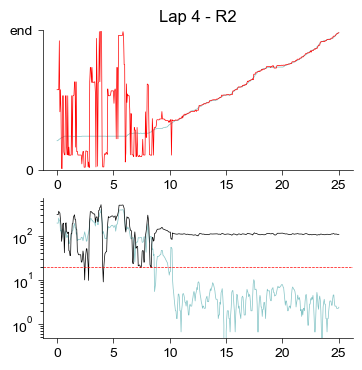

In [27]:
# Example Lap for Rereference.
mouse = 10232
example_lap = 4
s=0
D = GetDMatrices(1, 48)
rt_convertor = [0, 1, 2, 3,0,0,4,5,6,0]
loss_thre = [
    (13.17+13.595)/2,
    19.553,
    19.695,
    25.028,
    18.995,
    16.860, 
    19.384
]

with open(join(save_dir, f"{mouse}_{s}.pkl"), 'rb') as f:
    res = pickle.load(f)
    
    y_test = res['y_test']
    y_pred = res['y_pred']
    lap = res['lap']
    r_test = res['r_test']
    time = res['ms_time']
    t_test = res['t_test']
    
    idx = np.where(
        (lap >= 0)
    )[0]
    y_test = y_test[idx]
    y_pred = y_pred[idx]
    lap = lap[idx]
    r_test = r_test[idx]
    time = time[idx]
    t_test = t_test[idx]
    
dlap = np.where(np.diff(lap) != 0)[0]+1
beg, end = np.concatenate(([0], dlap)), np.concatenate((dlap, [len(lap)]))
D = GetDMatrices(1, 48)

for i in range(beg.shape[0]):
    if i != example_lap:
        continue
    if t_test[beg[i]] == 'Shuffle':
        continue

    b, e = beg[i], end[i]
    rt = rt_convertor[int(r_test[b])]
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4, 4))
    ax1 = Clear_Axes(axes[0], close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    ax1.plot(
        time[b:e]-time[b], 
        D[y_test[b:e]-1, 0], 
        color=DSPPalette[rt_convertor[int(r_test[b])]],
        linewidth=0.5
    )
    ax1.plot(
        time[b:e]-time[b], 
        D[y_pred[b:e]-1, 0],
        color='red',
        linewidth=0.5
    )
    ax1.set_title(f"Lap {i} - R{rt_convertor[int(r_test[b])]+1}")
    ax1.set_ylim(0, np.max(D))
    ax1.set_yticks([0, np.max(D)], ['0', 'end'])
    
    ax2 = Clear_Axes(axes[1], close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    all_loss = [D[t,p] for t,p in zip(y_test[b:e]-1, y_pred[b:e]-1)]
    rel_loss = np.abs(D[y_pred[b:e]-1, 0] - D[y_test[b:e]-1, SP_DSPs[1][rt]-1])
    
    all_loss = np.convolve(all_loss, np.ones(3), mode='same') / np.convolve(np.ones_like(all_loss), np.ones(3), mode='same')
    rel_loss = np.convolve(rel_loss, np.ones(3), mode='same') / np.convolve(np.ones_like(rel_loss), np.ones(3), mode='same')
    
    ax2.plot(time[b:e]-time[b], all_loss, color=DSPPalette[rt_convertor[int(r_test[b])]], linewidth=0.5)
    ax2.plot(time[b:e]-time[b], rel_loss, color='k', linewidth=0.5)
    ax2.axhline(loss_thre[rt], color='r', linestyle='--', linewidth=0.5)
    ax2.semilogy()
    plt.savefig(join(loc, f"[Example Loss]_{mouse}_S{s}_Lap_{i}.png"), dpi=300)
    plt.savefig(join(loc, f"[Example Loss]_{mouse}_S{s}_Lap_{i}.svg"), dpi=300)
    plt.show()


# Decoding Error Distribution

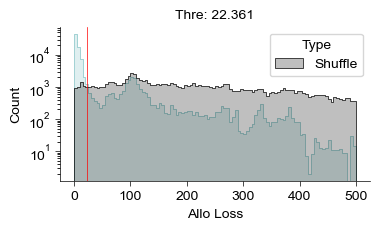

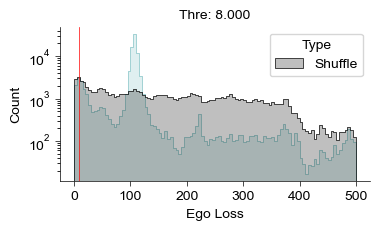

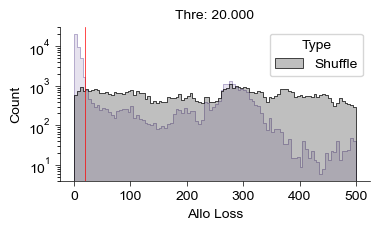

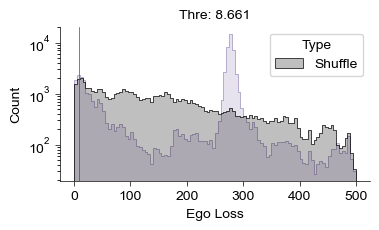

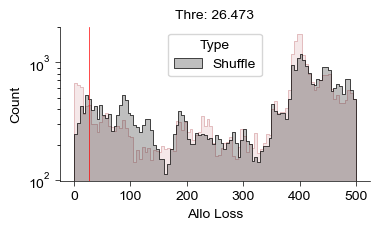

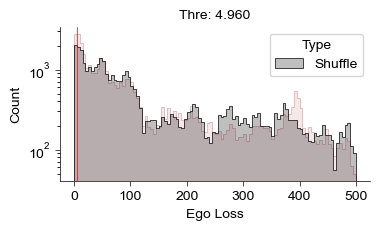

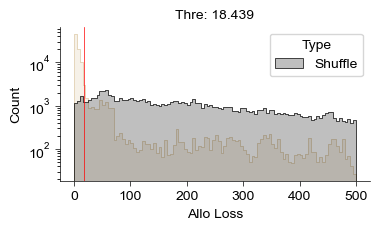

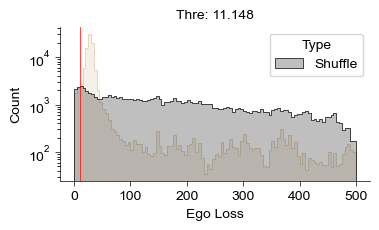

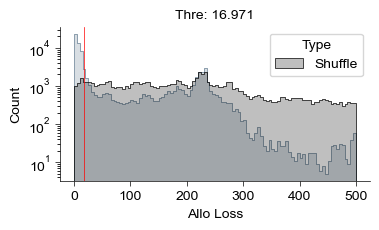

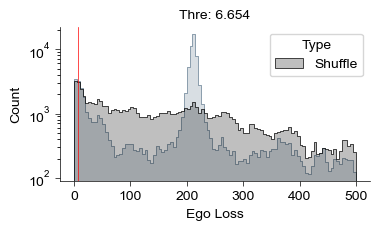

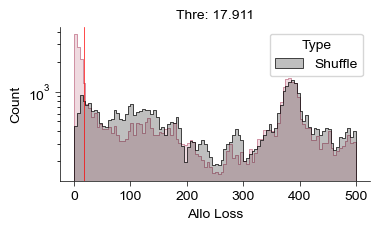

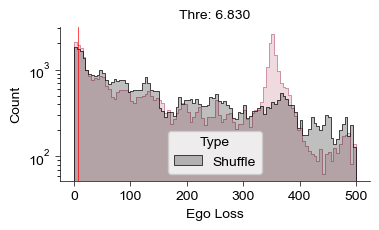

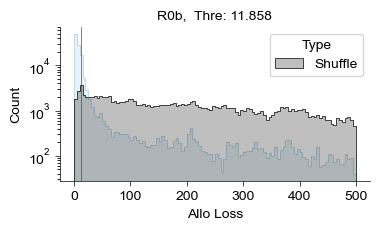

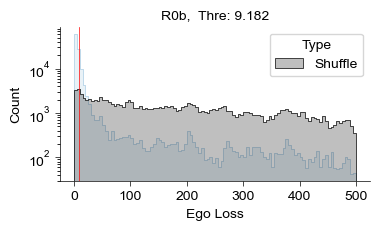

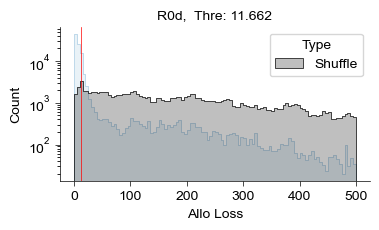

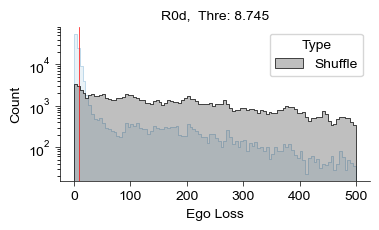

In [83]:
distribute_dir = join(loc, "Loss Distribution")
os.makedirs(distribute_dir, exist_ok=True)

for n, rt in zip([1,2,3,6,7,8,4, 9], [1,2,3,4,5,6,0,0]):
    subdata_rt = SubDict(
        DecodePI, 
        DecodePI.keys(),
        np.where((DecodePI["Route"] == n)&(DecodePI["Type"] == "Data"))[0]
    )

    subdata_shuf = SubDict(
        DecodePI, 
        DecodePI.keys(),
        np.where((DecodePI["Route"] == n)&(DecodePI["Type"] == "Shuffle"))[0]
    )
    fig = plt.figure(figsize=(4, 2))
    ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    sns.histplot(
        x='Allo Loss',
        ax=ax,
        hue='Type',
        data=subdata_rt,
        binrange=(0,500),
        bins=100,
        multiple='layer',
        element='step',
        palette=[DSPPalette[rt]],
        linewidth=0.5
    )
    sns.histplot(
        x='Allo Loss',
        ax=ax,
        hue='Type',
        data=subdata_shuf,
        binrange=(0,500),
        bins=100,
        multiple='layer',
        element='step',
        palette=['k'],
        linewidth=0.5
    )
    loss_thre = np.percentile(subdata_shuf['Allo Loss'], 5)
    ax.axvline(loss_thre, linewidth=0.5, color='r')
    ax.semilogy()
    ax.set_title(f'Thre: {loss_thre:.3f}', fontsize=10)
    if n in [4, 9]:
        if n == 4: 
            ax.set_title(f'R0b,  Thre: {loss_thre:.3f}', fontsize=10)
            plt.savefig(join(distribute_dir, f"Loss Distribution [R0b].png"), dpi=600)
            plt.savefig(join(distribute_dir, f"Loss Distribution [R0b].svg"), dpi=600)
        else:
            ax.set_title(f'R0d,  Thre: {loss_thre:.3f}', fontsize=10)
            plt.savefig(join(distribute_dir, f"Loss Distribution [R0d].png"), dpi=600)
            plt.savefig(join(distribute_dir , f"Loss Distribution [R0d].svg"), dpi=600) 
    else:
        plt.savefig(join(distribute_dir , f"Loss Distribution [R{rt}].png"), dpi=600)
        plt.savefig(join(distribute_dir , f"Loss Distribution [R{rt}].svg"), dpi=600)
    plt.show()

    fig = plt.figure(figsize=(4, 2))
    ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    sns.histplot(
        x='Ego Loss',
        ax=ax,
        hue='Type',
        data=subdata_rt,
        binrange=(0,500),
        bins=100,
        multiple='layer',
        element='step',
        palette=[DSPPalette[rt]],
        linewidth=0.5
    )
    sns.histplot(
        x='Ego Loss',
        ax=ax,
        hue='Type',
        data=subdata_shuf,
        binrange=(0,500),
        bins=100,
        multiple='layer',
        element='step',
        palette=['k'],
        linewidth=0.5
    )
    loss_thre = np.percentile(subdata_shuf['Ego Loss'], 5)
    ax.axvline(loss_thre, linewidth=0.5, color='r')
    ax.semilogy()
    ax.set_title(f'Thre: {loss_thre:.3f}', fontsize=10)
    if n in [4, 9]:
        if n == 4: 
            ax.set_title(f'R0b,  Thre: {loss_thre:.3f}', fontsize=10)
            plt.savefig(join(distribute_dir, f"Ego Loss Distribution [R0b].png"), dpi=600)
            plt.savefig(join(distribute_dir, f"Ego Loss Distribution [R0b].svg"), dpi=600)
        else:
            ax.set_title(f'R0d,  Thre: {loss_thre:.3f}', fontsize=10)
            plt.savefig(join(distribute_dir, f"Ego Loss Distribution [R0d].png"), dpi=600)
            plt.savefig(join(distribute_dir , f"Ego Loss Distribution [R0d].svg"), dpi=600) 
    else:
        plt.savefig(join(distribute_dir , f"Ego Loss Distribution [R{rt}].png"), dpi=600)
        plt.savefig(join(distribute_dir , f"Ego Loss Distribution [R{rt}].svg"), dpi=600)
    plt.show()


2470 237973


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24772\3927129210.py:57: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24772\3927129210.py:73: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24772\3927129210.py:88: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_24772\3927129210.py:103: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(


4064 100798
6072 98925
3710 87562
6760 60855
7236 40519


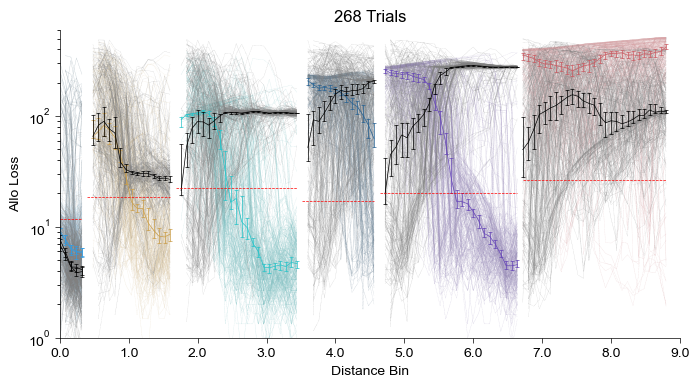

'\n\nfor n, rt in zip([1,2,3,6,7,8,4], [1, 2, 3, 4, 5, 6, 0]):\n    if n != 4:\n        subdata_rt = SubDict(\n            AvgDecodePI, \n            AvgDecodePI.keys(),\n            np.where((AvgDecodePI["Route"] == n)&(AvgDecodePI["Type"] == "Data"))[0]\n        )\n        subdata_shuf = SubDict(\n            DecodePI, \n            DecodePI.keys(),\n            np.where((DecodePI["Route"] == n)&(DecodePI["Type"] == "Shuffle"))[0]\n        )\n    else:\n        subdata_rt = SubDict(\n            AvgDecodePI, \n            AvgDecodePI.keys(),\n            np.where((np.isin(AvgDecodePI["Route"], [4, 9]))&(AvgDecodePI["Type"] == "Data"))[0]\n        )\n        subdata_shuf = SubDict(\n            DecodePI, \n            DecodePI.keys(),\n            np.where((np.isin(DecodePI["Route"], [4, 9]))&(DecodePI["Type"] == "Shuffle"))[0]\n        )\n\n    loss_thre = np.percentile(subdata_shuf[\'Allo Loss\'], 5)\n    loss_thre_ego = np.percentile(subdata_shuf[\'Ego Loss\'], 5)\n\n    median_los

In [8]:

DSPPaletteDeep = ["#369BDF", "#28C4C9", "#6646B7", "#CA5C63", "#CB9E49", "#276293", "#C12451"]

y_ranges = [
    [0, 5],
    [5, 21],
    [21, 44],
    [44, 58],
    [58, 84],
    [84, 111]
]
fig = plt.figure(figsize=(8, 4))
ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
for i, n, rt in zip(np.arange(6), [4,6,1,7,2,3], [0,4,1,5,2,3]):
    if n != 4:
        subdata_rt = SubDict(
            AvgDecodePI, 
            AvgDecodePI.keys(),
            np.where(
                (AvgDecodePI["Route"] == n)&
                (AvgDecodePI["Type"] == "Data")&
                (AvgDecodePI["Distance Bin"] >= y_ranges[i][0])&
                (AvgDecodePI["Distance Bin"] < y_ranges[i][1])
            )[0]
        )
        subdata_shuf = SubDict(
            DecodePI, 
            DecodePI.keys(),
            np.where(
                (DecodePI["Route"] == n)&
                (DecodePI["Type"] == "Shuffle")
            )[0]
        )
    else:
        subdata_rt = SubDict(
            AvgDecodePI, 
            AvgDecodePI.keys(),
            np.where(
                (np.isin(AvgDecodePI["Route"], [4, 9]))&
                (AvgDecodePI["Type"] == "Data")&
                (AvgDecodePI["Distance Bin"] >= y_ranges[i][0])&
                (AvgDecodePI["Distance Bin"] < y_ranges[i][1])
            )[0]
        )
        subdata_shuf = SubDict(
            DecodePI, 
            DecodePI.keys(),
            np.where(
                (np.isin(DecodePI["Route"], [4, 9]))&
                (DecodePI["Type"] == "Shuffle")
            )[0]
        )
    
    print(len(subdata_rt['Allo Loss']), len(subdata_shuf['Allo Loss']))
    loss_thre = np.percentile(subdata_shuf['Allo Loss'], 5)
    loss_thre_ego = np.percentile(subdata_shuf['Ego Loss'], 5)
    
    sns.lineplot(
        x='Distance Bin',
        y='Allo Loss',
        hue='Route',
        style='Lap',
        data=subdata_rt,
        palette=[DSPPalette[rt]],
        ax=ax,
        linewidth=0.2,
        err_kws={'edgecolor': None},
        estimator=np.median,
        legend=False,
        zorder=1,
        alpha=0.5
    )

    sns.lineplot(
        x='Distance Bin',
        y='Allo Loss',
        hue='Route',
        data=subdata_rt,
        palette=[DSPPaletteDeep[rt]],
        ax=ax,
        linewidth=0.5,
        err_style='bars',
        err_kws={'capsize': 1.5, 'linewidth': 0.5, 'capthick': 0.5},
        estimator=np.median,
        legend=False,
        zorder=2,
    )

    sns.lineplot(
        x='Distance Bin',
        y='Ego Loss',
        hue="Route",
        style="Lap",
        data=subdata_rt,
        palette=['gray'],
        ax=ax,
        linewidth=0.2,
        err_kws={'edgecolor': None},
        estimator=np.nanmedian,
        legend=False,
        zorder=1,
        alpha=0.5
    )
    sns.lineplot(
        x='Distance Bin',
        y='Ego Loss',
        hue="Route",
        data=subdata_rt,
        palette=['k'],
        ax=ax,
        linewidth=0.5,
        err_style='bars',
        err_kws={'capsize': 1.5, 'linewidth': 0.5, 'capthick': 0.5},
        estimator=np.nanmedian,
        legend=False,
        zorder=2,
    )
    ax.plot([y_ranges[i][0], y_ranges[i][1]-1], [loss_thre, loss_thre], linestyle='--', color='r', linewidth=0.5)
    ax.set_title(f"{np.unique(subdata_rt['Lap']).shape[0]} Trials")
    
ax.semilogy()
ax.set_xticks(np.linspace(0, 112.5,10), np.linspace(0,9,10))
ax.set_xlim(0, 112.5)
ax.set_ylim(1,600)
plt.show()
    
"""
          
for n, rt in zip([1,2,3,6,7,8,4], [1, 2, 3, 4, 5, 6, 0]):
    if n != 4:
        subdata_rt = SubDict(
            AvgDecodePI, 
            AvgDecodePI.keys(),
            np.where((AvgDecodePI["Route"] == n)&(AvgDecodePI["Type"] == "Data"))[0]
        )
        subdata_shuf = SubDict(
            DecodePI, 
            DecodePI.keys(),
            np.where((DecodePI["Route"] == n)&(DecodePI["Type"] == "Shuffle"))[0]
        )
    else:
        subdata_rt = SubDict(
            AvgDecodePI, 
            AvgDecodePI.keys(),
            np.where((np.isin(AvgDecodePI["Route"], [4, 9]))&(AvgDecodePI["Type"] == "Data"))[0]
        )
        subdata_shuf = SubDict(
            DecodePI, 
            DecodePI.keys(),
            np.where((np.isin(DecodePI["Route"], [4, 9]))&(DecodePI["Type"] == "Shuffle"))[0]
        )
        
    loss_thre = np.percentile(subdata_shuf['Allo Loss'], 5)
    loss_thre_ego = np.percentile(subdata_shuf['Ego Loss'], 5)
    
    median_loss = np.zeros(111)
    median_loss_ego = np.zeros(111)
    for i in range(111):
        idx = np.where(subdata_rt['Distance Bin'] == i)[0]
        if idx.shape[0] > 0:
            median_loss[i] = np.nanmedian(subdata_rt['Allo Loss'][idx])
            median_loss_ego[i] = np.nanmedian(subdata_rt['Ego Loss'][idx])
        else:
            median_loss[i] = np.nan
            median_loss_ego[i] = np.nan

    fig = plt.figure(figsize=(4, 2))
    ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
 
    
    #plt.savefig(join(loc, f"R{n}_Loss.png"), dpi=300)
    #plt.savefig(join(loc, f"R{n}_Loss.svg"), dpi=300)
    ax.axvline(5, linestyle='--', color='k', linewidth=0.5)
    ax.axvline(21, linestyle='--', color='k', linewidth=0.5)
    ax.axvline(44, linestyle='--', color='k', linewidth=0.5)
    ax.axvline(58, linestyle='--', color='k', linewidth=0.5)
    ax.axvline(84, linestyle='--', color='k', linewidth=0.5)
    
    plt.show()
"""

# Illustration of Loss

Graph with 69 nodes and 89 edges


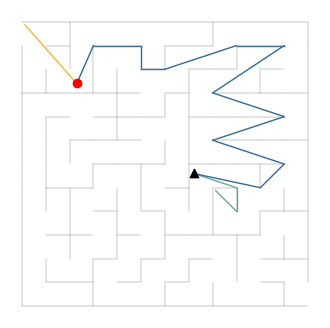

In [62]:
from mazepy.behav.graph import Graph

G = Graph(12, 12, maze1_graph)
fig = plt.figure(figsize=(4, 4))
ax = Clear_Axes(plt.axes())
DrawMazeProfile(axes=ax,maze_type=1, color='gray', linewidth=0.3, nx=12)
G.plot_shortest_path(
    (7.2, 6.4), 
    (8.125, 7.125),
    ax=ax, 
    linewidth=1,
    #marker='o',
    #markeredgewidth=0,
    #markersize=7,
    color='#6ba8a3',
    is_show_nodes=False,
    zorder=1
)
G.plot_shortest_path(
    (2.3, 2.6), 
    (0.125, 0.125),
    ax=ax, 
    linewidth=1,
    #marker='s',
    #markeredgewidth=0,
    #markersize=7,
    color='#f8b62d',
    is_show_nodes=False,
    zorder=1
)
G.plot_shortest_path(
    (7.2, 6.4), 
    (2.3, 2.6),
    ax=ax, 
    linewidth=1,
    #marker='^',
    #markeredgewidth=0,
    #markersize=7,
    color='#2f6b9c',
    is_show_nodes=False,
    zorder=1
)
ax.scatter([7.2-0.5], [6.4-0.5], color='k', marker='^', zorder=2, edgecolors=None)
ax.scatter([2.3-0.5], [2.6-0.5], color='r', marker='o', zorder=2, edgecolors=None)
ax.invert_yaxis()
plt.savefig(join(loc, "PI Loss Illustrator.png"), dpi=300)
plt.savefig(join(loc, "PI Loss Illustrator.svg"), dpi=300)
plt.show()

# Correlation

  Mean: 0.1060396677544221, STD: 0.03198188284658804, Max: 0.162722357783956, Min: 0.05864651360599226, Median: 0.10354782055120965, df: 5


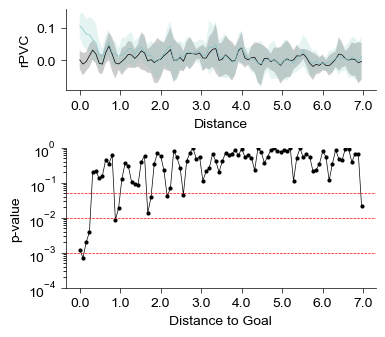

  Mean: 0.0802709086451563, STD: 0.031965999468097056, Max: 0.14349056662551066, Min: 0.04411945617090764, Median: 0.0737274356894814, df: 5


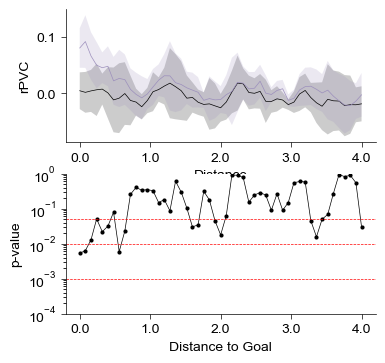

  Mean: 0.05872934211947948, STD: 0.04380768084781951, Max: 0.12237477729149406, Min: -0.01043683484509005, Median: 0.0528429606427397, df: 5


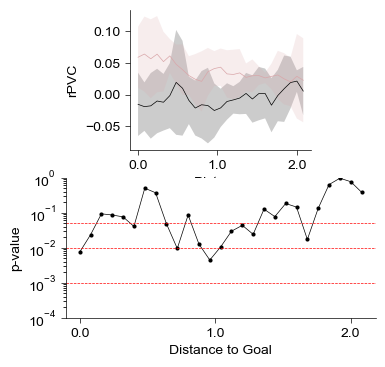

  Mean: 0.11278730296919152, STD: 0.03282310937524057, Max: 0.15890882356048466, Min: 0.06322920041377125, Median: 0.11544779102079072, df: 5


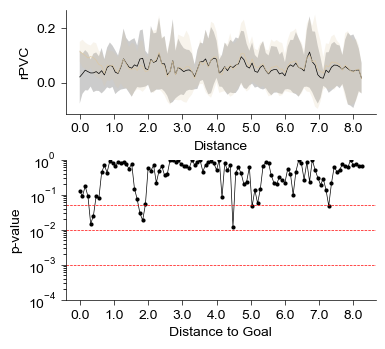

  Mean: 0.08682562800034264, STD: 0.010962843522452817, Max: 0.10816051186122945, Min: 0.07309316361430461, Median: 0.08464875776146119, df: 5


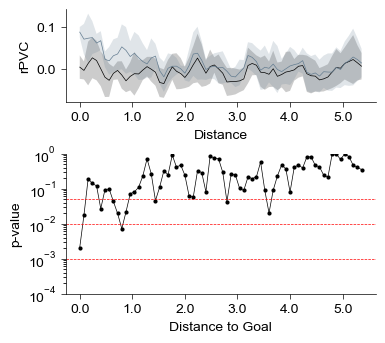

  Mean: 0.03831809929986147, STD: 0.022461738881449686, Max: 0.08310933048196374, Min: 0.01669093413263368, Median: 0.030110025551615786, df: 5


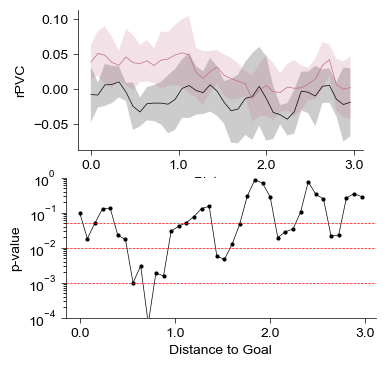

[4. 3. 2. 0. 2. 0.]


In [29]:
if exists(join(figdata, f"{code_id} [rpvc].pkl")) == False:
    PVCs = {
        'MiceID': [],
        'Route': [],
        'Nodes': [],
        'Session': [],
        'Distance': [],
        'rPVC': [],
        'Type': []
    }
    D = GetDMatrices(1, 48)

    r0_bins = CP_DSPs[1][0]
    for mouse in [10212, 10224, 10227, 10232, 10275, 10276]:
        file_idx = np.where(f2['MiceID'] == mouse)[0]
        for s in tqdm(range(7)):
            with open(f2['Trace File'][file_idx[s]], 'rb') as f:
                trace = pickle.load(f)
                
            for rt, nodes in zip([1,2,3,4,5,6], [1,2,3,6,7,8]):
                targ_nodes = 0 if rt in [1,2,3] else 5
                targ_nodes2 = 4 if rt in [1,2,3] else 9
                
                bins = CP_DSPs[trace['maze_type']][rt]
                if rt in [1, 2, 3]:
                    bins_ctrl = bins.copy()
                elif rt == 4:
                    bins_ctrl = np.concatenate([[4, 5], bins[2:]])
                elif rt == 5:
                    bins_ctrl = np.concatenate([[84, 83, 95], bins[3:]])
                elif rt == 6:
                    bins_ctrl = np.concatenate([[61, 73, 85, 97], bins[4:]])
                
                rpvc = np.zeros(bins.shape[0])
                rpvc_ctrl = np.zeros(bins.shape[0])
                
                placecell_idx = np.where(
                    (trace[f'node {targ_nodes}']['is_placecell'] == 1) |
                    (trace[f'node {targ_nodes2}']['is_placecell'] == 1)
                )[0]
                
                for i in range(bins.shape[0]):
                    sonbins = np.asarray(Father2SonGraph[bins[i]]).astype(np.int64)
                    sonbins_ctrl = np.asarray(Father2SonGraph[bins_ctrl[i]]).astype(np.int64)
                    sonbins_r0 = np.asarray(Father2SonGraph[r0_bins[i]]).astype(np.int64)
                    
                    rpvc[i] = np.nanmean(np.asarray([
                        np.corrcoef(
                            trace[f'node {nodes}']['smooth_map_all'][placecell_idx, sonbins[n] - 1],
                            trace[f'node {targ_nodes}']['smooth_map_all'][placecell_idx, sonbins_r0[n] - 1]
                        )[0,1] for n in range(sonbins.shape[0])
                    ]))
                    rpvc_ctrl[i] = np.nanmean(np.asarray([
                        np.corrcoef(
                            trace[f'node {targ_nodes2}']['smooth_map_all'][placecell_idx, sonbins_ctrl[n] - 1],
                            trace[f'node {targ_nodes}']['smooth_map_all'][placecell_idx, sonbins_r0[n] - 1]
                        )[0,1] for n in range(sonbins_r0.shape[0])
                    ]))
 
                    PVCs['MiceID'].append([mouse, mouse])
                    PVCs['Route'].append([rt, rt])
                    PVCs['Nodes'].append([nodes, targ_nodes2])
                    PVCs['Session'].append([s, s])
                    PVCs['Distance'].append([i, i])
                    PVCs['rPVC'].append([rpvc[i], rpvc_ctrl[i]])
                    PVCs['Type'].append(["Data", "Ctrl"])
            
            del trace
            
    for key in PVCs.keys():
        PVCs[key] = np.concatenate(PVCs[key])
    with open(join(figdata, f"{code_id} [rpvc].pkl"), 'wb') as f:
        pickle.dump(PVCs, f)

    PVCsD = pd.DataFrame(PVCs)
    PVCsD.to_excel(join(figdata, f"{code_id} [rpvc].xlsx"), index=False)
    print(len(PVCsD)) 
else:
    with open(join(figdata, f"{code_id} [rpvc].pkl"), 'rb') as f:
        PVCs = pickle.load(f)
        
if exists(join(figdata, f"{code_id} [Avg].pkl")) == False:
    avg_PVCs = {
        'MiceID': [],
        'Route': [],
        'Distance': [],
        'rPVC': [],
        'Type': []
    }
        
    for mouse in tqdm([10212, 10224, 10227, 10232, 10275, 10276]):
        for rt in range(1,7):
            for b in range(111):
                for ttype in ['Data', 'Ctrl']:
                    idx = np.where((PVCs['Route'] == rt)&(PVCs['MiceID'] == mouse)&(PVCs['Distance'] == b)&(PVCs['Type'] == ttype))[0]
                    if len(idx) > 0:
                        avg_PVCs['MiceID'].append(mouse)
                        avg_PVCs['Route'].append(rt)
                        avg_PVCs['Distance'].append(b)
                        avg_PVCs['rPVC'].append(np.nanmean(PVCs['rPVC'][idx]))
                        avg_PVCs['Type'].append(PVCs['Type'][idx][0])

    for key in avg_PVCs.keys():
        avg_PVCs[key] = np.asarray(avg_PVCs[key])
    with open(join(figdata, f"{code_id} [Avg].pkl"), 'wb') as f:
        pickle.dump(avg_PVCs, f)

    avg_PVCsD = pd.DataFrame(avg_PVCs)
    avg_PVCsD.to_excel(join(figdata, f"{code_id} [Avg].xlsx"), index=False)
    print(len(avg_PVCsD))
else:
    with open(join(figdata, f"{code_id} [Avg].pkl"), 'rb') as f:
        avg_PVCs = pickle.load(f)

D = GetDMatrices(1, 48)
PVCs['Distance'] = ((PVCs['Distance'] / (np.max(D)+1e-10) * 111)//1).astype(np.int64) * 8
SP_referenced_bins = np.zeros(6)
for rt in [1,2,3,4,5,6]:
    subdata_rt = SubDict(
        avg_PVCs,
        avg_PVCs.keys(),
        np.where((avg_PVCs['Route'] == rt))[0]
    )
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(4,4))
    ax = Clear_Axes(axes[0], close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    subdata_rt['Distance'] = subdata_rt['Distance'].astype(np.float64) / 100
    sns.lineplot(
        x='Distance',
        y='rPVC',
        data=subdata_rt,
        hue='Type',
        linewidth=0.5,
        palette=['k', DSPPalette[rt]],
        hue_order=['Ctrl', 'Data'],
        err_kws={'edgecolor': None},
        legend=False,
        errorbar='sd',
        ax=ax
    )
    ax.set_aspect('equal')
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    ax2 = Clear_Axes(axes[1], close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    unique_dist = np.unique(subdata_rt['Distance'])
    pvalues = np.zeros(unique_dist.shape[0])
    for i, d in enumerate(unique_dist):
        idx = np.where((subdata_rt['Distance'] == d)&(subdata_rt['Type'] == 'Data'))[0]
        idx_ctrl = np.where((subdata_rt['Distance'] == d)&(subdata_rt['Type'] == 'Ctrl'))[0]
        
        idx_filter = np.where(np.isnan(subdata_rt['rPVC'][idx]) == False)[0]
        idx_ctrl_filter = np.where(np.isnan(subdata_rt['rPVC'][idx_ctrl]) == False)[0]
        idx = idx[idx_filter]
        idx_ctrl = idx_ctrl[idx_ctrl_filter]
        
        if i == 0:
            print_estimator(subdata_rt['rPVC'][idx])
        pvalues[i] = ttest_rel(subdata_rt['rPVC'][idx], subdata_rt['rPVC'][idx_ctrl]).pvalue
        
    ax2.plot(unique_dist, pvalues, color='k', linewidth=0.5, marker='o', markersize=3, markeredgewidth=0)
    
    first_nonsignificant_bin = np.where(pvalues >= 0.05)[0]
    if len(first_nonsignificant_bin) > 0:
        SP_referenced_bins[rt-1] = first_nonsignificant_bin[0]
    else:
        SP_referenced_bins[rt-1] = unique_dist.shape[0]
    
    ax2.axhline(0.05, color='r', linestyle='--', linewidth=0.5)
    ax2.axhline(0.01, color='r', linestyle='--', linewidth=0.5)
    ax2.axhline(0.001, color='r', linestyle='--', linewidth=0.5)
    ax2.axhline(0.0001, color='r', linestyle='--', linewidth=0.5)
    ax2.set_ylim(1e-4, 1)
    ax2.set_xlabel('Distance to Goal')
    ax2.set_ylabel('p-value')
    ax2.semilogy()
    
    ax.set_xticks(np.linspace(0, 1.125, 10), np.linspace(0, 9, 10))
    ax2.set_xticks(np.linspace(0, 1.125, 10), np.linspace(0, 9, 10))
    ax.set_xlim(xlims)
    ax2.set_xlim(xlims)
    plt.savefig(join(loc, f"rPVC_R{rt+1}.png"), dpi=300)
    plt.savefig(join(loc, f"rPVC_R{rt+1}.svg"), dpi=300)
    plt.show()

print(SP_referenced_bins)

(89, 3)


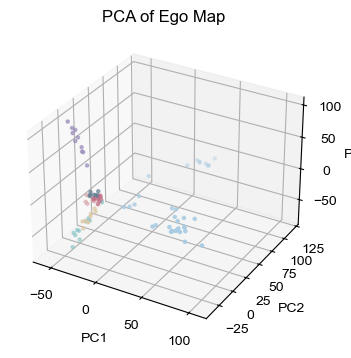

In [53]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
# Transform to route, bin, nneuron
ego_map_reshaped = ego_map.transpose(2, 1, 0).reshape(ego_map.shape[2], -1)
pca_result = pca.fit_transform(ego_map_reshaped)
print(pca_result.shape)
plt.figure(figsize=(6, 4))
ax = plt.axes(projection='3d')
ax.scatter(pca_result[:, 0], pca_result[:, 1], pca_result[:, 2], s=5, c=DSPPaletteRGBA[route])
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.title('PCA of Ego Map')
plt.show()

pca = 